# Práctica 1: Uso de embeddings preentrenados

Adaptación del modelo LSTM del Notebook 13 (clasificación de AG_NEWS) para usar embeddings GloVe preentrenados, y comparación con embeddings aleatorios y entre distintos tamaños (50d, 100d, 200d y 300d).

## 1. Instalación

In [ ]:
%pip install huggingface_hub

^C
Note: you may need to restart the kernel to use updated packages.


## 2. Datos y vocabulario

In [ ]:
import re, csv, os, time, io, zipfile, urllib.request
from collections import Counter
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

BASE_URL = "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/"

def load_ag_news(split):
    path = f"ag_news_{split}.csv"
    if not os.path.exists(path):
        urllib.request.urlretrieve(BASE_URL + f"{split}.csv", path)
    data = []
    with open(path, encoding="utf-8") as f:
        for label, title, desc in csv.reader(f):
            text = (title + " " + desc).replace("\\", " ")
            data.append((int(label) - 1, text))
    return data

train_raw = load_ag_news("train")
test_raw = load_ag_news("test")
print(len(train_raw), "noticias de entrenamiento,", len(test_raw), "de test")

def tokenizer(text):
    return re.findall(r"\w+|[^\w\s]", text.lower())

counter = Counter()
for _, text in train_raw:
    counter.update(tokenizer(text))

itos = ["<pad>", "<unk>"] + [w for w, _ in counter.most_common()]
stoi = {w: i for i, w in enumerate(itos)}

class Vocab:
    """Interfaz mínima de vocabulario que usan las celdas siguientes."""
    def __init__(self, stoi): self.stoi = stoi
    def __len__(self): return len(self.stoi)
    def __getitem__(self, tok): return self.stoi.get(tok, self.stoi["<unk>"])
    def __call__(self, tokens): return [self[t] for t in tokens]
    def get_stoi(self): return self.stoi

vocab = Vocab(stoi)
print("Tamaño del vocabulario:", len(vocab))

text_pipeline = lambda x: vocab(tokenizer(x))

Dispositivo: cpu
120000 noticias de entrenamiento, 7600 de test


KeyboardInterrupt: 

## 3. DataLoaders

In [ ]:
train_ds = [(label, text_pipeline(text)) for label, text in train_raw]
test_ds = [(label, text_pipeline(text)) for label, text in test_raw]

def collate_batch(batch):
    labels = torch.tensor([label for label, _ in batch], dtype=torch.long)
    texts = [torch.tensor(ids, dtype=torch.long) for _, ids in batch]
    padded = nn.utils.rnn.pad_sequence(texts, batch_first=True, padding_value=vocab["<pad>"])
    return labels, padded

train_dataloader = DataLoader(train_ds, batch_size=64, shuffle=True, collate_fn=collate_batch)
test_dataloader = DataLoader(test_ds, batch_size=64, shuffle=False, collate_fn=collate_batch)

## 4. Descarga de GloVe

In [ ]:
from huggingface_hub import hf_hub_download

glove_zip = hf_hub_download(repo_id="stanfordnlp/glove", filename="glove.6B.zip")
print("Descargado en:", glove_zip)

with zipfile.ZipFile(glove_zip) as z:
    print(z.namelist())

c:\Users\Carlota\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Carlota\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Carlota\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to 

Descargado en: C:\Users\Carlota\.cache\huggingface\hub\models--stanfordnlp--glove\snapshots\1db2080b2d94def6e5b0386a523102f9d8849e9d\glove.6B.zip
['glove.6B.100d.txt', 'glove.6B.200d.txt', 'glove.6B.300d.txt', 'glove.6B.50d.txt']


c:\Users\Carlota\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Carlota\.cache\huggingface\hub\models--stanfordnlp--glove. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


## 5. Matriz de embeddings a partir del vocabulario

Se leen solo las palabras de GloVe que están en nuestro vocabulario. Las que no aparecen se inicializan al azar y `<pad>` se deja a cero.

In [ ]:
def build_embedding_matrix(zip_path, dim):
    filename = f"glove.6B.{dim}d.txt"
    stoi = vocab.get_stoi()
    found = {}

    with zipfile.ZipFile(zip_path) as z, z.open(filename) as f:
        for line in io.TextIOWrapper(f, encoding="utf-8"):
            parts = line.rstrip().split(" ")
            word = parts[0]
            if word in stoi:
                found[word] = np.asarray(parts[1:], dtype=np.float32)

    rng = np.random.default_rng(0)
    matrix = rng.normal(0, 0.1, (len(vocab), dim)).astype(np.float32)
    
    for word, vec in found.items():
        matrix[stoi[word]] = vec

    matrix[stoi["<pad>"]] = 0.0

    coverage = len(found) / len(vocab)
    print(f"GloVe {dim}d: {len(found)} de {len(vocab)} palabras encontradas ({coverage:.1%})")
    return torch.from_numpy(matrix)

## 6. Modelo

In [ ]:
class LSTMTextClassificationModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_class,
                 pretrained_embeddings=None, freeze_embeddings=False):
        super().__init__()
        if pretrained_embeddings is not None:
            self.embedding = nn.Embedding.from_pretrained(
                pretrained_embeddings, freeze=freeze_embeddings,
                padding_idx=vocab["<pad>"]
            )
        else:
            self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_class)

    def forward(self, text):
        lengths = (text != vocab["<pad>"]).sum(dim=1)

        embedded = self.embedding(text)
        lstm_out, _ = self.lstm(embedded)

        batch_indices = torch.arange(
            text.size(0), device=text.device
        )
        last_output = lstm_out[batch_indices, lengths - 1, :]

        return self.fc(last_output)

## 7. Entrenamiento y evaluación

In [ ]:
EPOCHS = 10
LR = 5
HIDDEN_DIM = 64
NUM_CLASS = 4

def train_epoch(model, dataloader, criterion, optimizer):
    model.train()
    total_acc, total_count = 0, 0
    for label, text in dataloader:
        label, text = label.to(device), text.to(device)
        optimizer.zero_grad()
        pred = model(text)
        loss = criterion(pred, label)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 0.1)
        optimizer.step()
        total_acc += (pred.argmax(1) == label).sum().item()
        total_count += label.size(0)
    return total_acc / total_count

def evaluate(model, dataloader):
    model.eval()
    total_acc, total_count = 0, 0
    with torch.no_grad():
        for label, text in dataloader:
            label, text = label.to(device), text.to(device)
            pred = model(text)
            total_acc += (pred.argmax(1) == label).sum().item()
            total_count += label.size(0)
    return total_acc / total_count

def run_experiment(name, embed_dim, pretrained=None, freeze=False):
    torch.manual_seed(0)
    model = LSTMTextClassificationModel(len(vocab), embed_dim, HIDDEN_DIM, NUM_CLASS,
                                        pretrained, freeze).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=LR)

    history = []
    print(f"\n=== {name} ===")
    for epoch in range(1, EPOCHS + 1):
        t0 = time.time()
        acc_train = train_epoch(model, train_dataloader, criterion, optimizer)
        acc_test = evaluate(model, test_dataloader)
        history.append(acc_test)
        print(f"Época {epoch:2d} | train {acc_train:.3f} | test {acc_test:.3f} | {time.time()-t0:.1f}s")
    return history

## 8. Experimentos

In [ ]:
results = {}

results["Aleatorio 32d"] = run_experiment("Aleatorio 32d", 32)

for dim in [50, 100, 200, 300]:
    emb = build_embedding_matrix(glove_zip, dim)
    results[f"GloVe {dim}d"] = run_experiment(f"GloVe {dim}d", dim, emb, freeze=False)


=== Aleatorio 32d ===
Época  1 | train 0.256 | test 0.249 | 29.3s
Época  2 | train 0.447 | test 0.670 | 28.4s
Época  3 | train 0.751 | test 0.799 | 28.6s
Época  4 | train 0.831 | test 0.838 | 29.0s
Época  5 | train 0.863 | test 0.867 | 27.6s
Época  6 | train 0.882 | test 0.870 | 27.9s
Época  7 | train 0.895 | test 0.875 | 28.2s
Época  8 | train 0.906 | test 0.880 | 28.6s
Época  9 | train 0.914 | test 0.879 | 29.3s
Época 10 | train 0.922 | test 0.883 | 29.4s
GloVe 50d: 57064 de 65062 palabras encontradas (87.7%)

=== GloVe 50d ===
Época  1 | train 0.291 | test 0.476 | 32.3s
Época  2 | train 0.826 | test 0.884 | 31.7s
Época  3 | train 0.899 | test 0.904 | 31.3s
Época  4 | train 0.913 | test 0.910 | 31.4s
Época  5 | train 0.923 | test 0.913 | 31.4s
Época  6 | train 0.930 | test 0.913 | 29.4s
Época  7 | train 0.936 | test 0.916 | 29.4s
Época  8 | train 0.940 | test 0.919 | 31.6s
Época  9 | train 0.946 | test 0.918 | 32.7s
Época 10 | train 0.949 | test 0.920 | 32.0s
GloVe 100d: 57064 de 65

### Extra (opcional): embeddings congelados

In [ ]:
emb100 = build_embedding_matrix(glove_zip, 100)
results["GloVe 100d (congelado)"] = run_experiment("GloVe 100d congelado", 100, emb100, freeze=True)

GloVe 100d: 57064 de 65062 palabras encontradas (87.7%)

=== GloVe 100d congelado ===
Época  1 | train 0.319 | test 0.790 | 97.6s
Época  2 | train 0.868 | test 0.885 | 109.9s
Época  3 | train 0.897 | test 0.901 | 110.0s
Época  4 | train 0.907 | test 0.906 | 109.1s
Época  5 | train 0.913 | test 0.910 | 107.6s
Época  6 | train 0.919 | test 0.914 | 108.5s
Época  7 | train 0.922 | test 0.914 | 107.4s
Época  8 | train 0.925 | test 0.916 | 106.2s
Época  9 | train 0.929 | test 0.914 | 108.1s
Época 10 | train 0.931 | test 0.918 | 108.2s


## 9. Resultados

,Modelo,Exactitud final en test (%),Primera época >80%
0,Aleatorio 32d,88.30,4
1,GloVe 50d,92.00,2
2,GloVe 100d,92.38,2
3,GloVe 200d,92.05,1
4,GloVe 300d,92.57,1
5,GloVe 100d (congelado),91.83,2


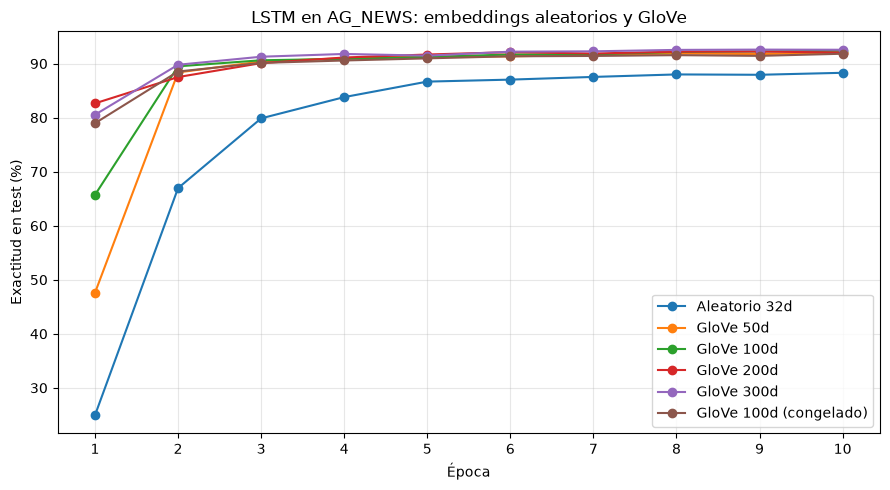

In [ ]:
summary = pd.DataFrame({
    "Modelo": list(results.keys()),
    "Exactitud final en test (%)": [
        h[-1] * 100 for h in results.values()
    ],
    "Primera época >80%": [
        next(
            (i + 1 for i, acc in enumerate(h) if acc > 0.8),
            None
        )
        for h in results.values()
    ],
})

summary["Primera época >80%"] = (summary["Primera época >80%"].astype("Int64"))

display(
    summary.style.format(
        {"Exactitud final en test (%)": "{:.2f}"},
        na_rep="—"
    )
)

plt.figure(figsize=(9, 5))

for name, history in results.items():
    plt.plot(
        range(1, len(history) + 1),
        [acc * 100 for acc in history],
        marker="o",
        label=name
    )

plt.xlabel("Época")
plt.ylabel("Exactitud en test (%)")
plt.title("LSTM en AG_NEWS: embeddings aleatorios y GloVe")
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Conclusiones

Los resultados muestran que utilizar embeddings preentrenados GloVe mejora la exactitud del modelo LSTM en la clasificación de noticias de AG_NEWS respecto a la referencia con embeddings aleatorios de 32 dimensiones.

**Efecto del uso de GloVe.** Todas las configuraciones preentrenadas superan a la referencia aleatoria. El mejor resultado corresponde a GloVe 300d, con una mejora de aproximadamente **4,28 puntos porcentuales**, calculada a partir de los valores sin redondear. Los vectores preentrenados aportan información sobre las relaciones entre palabras que el modelo puede aprovechar para clasificar las noticias.

**Efecto del tamaño de los embeddings.** Aumentar la dimensión no produce una mejora constante: GloVe 200d obtiene una exactitud ligeramente inferior a GloVe 100d. Aunque GloVe 300d alcanza el mayor resultado, su ventaja respecto a 100d es de solo 0,19 puntos porcentuales. Además, las configuraciones de mayor dimensión requieren más parámetros y, en esta ejecución, han tardado más por época. Por ello, GloVe 100d ofrece una alternativa razonable si se busca equilibrar exactitud y coste de entrenamiento.

**Evolución del aprendizaje.** Los modelos con GloVe superan el 80 % de exactitud en test en la primera o segunda época, mientras que el modelo aleatorio lo consigue en la cuarta. Esto indica que los embeddings preentrenados permiten alcanzar un buen resultado en menos épocas, aunque no necesariamente en menos tiempo total.

**Embeddings ajustables frente a congelados.** GloVe 100d alcanza un 92,38 % cuando sus vectores se actualizan durante el entrenamiento, frente al 91,83 % al mantenerlos congelados. En esta ejecución, adaptar los embeddings a la tarea mejora el resultado final.

**Alcance de la comparación.** Se ha mantenido la arquitectura LSTM de los apuntes y se han comparado los resultados tras 10 épocas. Las diferencias pequeñas deben interpretarse con cautela, ya que se ha realizado una única ejecución por configuración. Además, la referencia aleatoria utiliza 32 dimensiones, por lo que la comparación combina cambios en la inicialización y en el tamaño de los embeddings.